# Hit Song Prediction — Model Training Preprocessing

This notebook covers preprocessing, baseline model training, hyperparameter tuning, and final evaluation for the Hit Song Prediction project.

## Data Loading and Preprocessing

## 1. Import Libraries

In [54]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

## 2. Load the Dataset

In [55]:
final_df = pd.read_csv("../data/final_dataset.csv")
display(final_df.head())

,name,artists,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,hit
0,Perfidia Cha Cha,['Cal Tjader'],0.858,0.449,-16.531,0.0658,0.77400,0.062500,0.1130,0.890,127.066,0
1,Gir Kanıma,['Harun Kolçak'],0.759,0.714,-9.449,0.0564,0.00163,0.000012,0.0173,0.492,119.775,0
2,It's Over Now,['112'],0.660,0.710,-4.541,0.0409,0.01060,0.000007,0.0736,0.233,97.988,1
3,The Pusher,['Blind Melon'],0.438,0.576,-8.727,0.0320,0.03020,0.000011,0.0988,0.742,165.277,0
4,Toys In The Attic,['Aerosmith'],0.219,0.928,-9.997,0.0697,0.00100,0.000002,0.3410,0.446,197.462,0


## 3. Define Features and Target

In [56]:
audio_features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
]

X = final_df[audio_features]
y = final_df["hit"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10000, 9)
y shape: (10000,)


## 4. Train-Test Split

In [57]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (8000, 9)
X_test shape: (2000, 9)
y_train shape: (8000,)
y_test shape: (2000,)


## 5. Train-Test Class Distributions

In [58]:
train_distribution = pd.DataFrame({
    "count": y_train.value_counts().sort_index(),
    "percentage": (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
})
test_distribution = pd.DataFrame({
    "count": y_test.value_counts().sort_index(),
    "percentage": (y_test.value_counts(normalize=True).sort_index() * 100).round(2),
})

train_distribution.index.name = "hit"
test_distribution.index.name = "hit"

print("Training target distribution:")
display(train_distribution)

print("Testing target distribution:")
display(test_distribution)

Training target distribution:


,count,percentage
hit,,
0,4800,60.0
1,3200,40.0


Testing target distribution:


,count,percentage
hit,,
0,1200,60.0
1,800,40.0


## 6. Standardize the Features

In [59]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("First 5 rows of X_train_scaled:")
display(pd.DataFrame(X_train_scaled, columns=audio_features).head())

First 5 rows of X_train_scaled:


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,2.020043,-0.084098,0.630174,0.018609,0.847120,3.316982,-0.251117,-1.738506,0.062656
1,-0.242930,0.323112,-0.547809,-0.398663,-1.147916,-0.359454,-0.650879,1.113310,0.504710
2,-1.747434,1.498566,1.296369,0.494105,0.466033,-0.359595,-0.614277,-0.650577,-1.735174
3,0.944509,0.352499,0.126869,-0.300410,0.916135,-0.327266,0.715406,1.617277,-0.015393
4,1.081282,-0.210040,0.570999,-0.414432,0.589061,-0.359595,0.332228,0.169370,-0.453356


## Model Training

In [60]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

## Logistic Regression

In [61]:
logistic_regression = LogisticRegression(max_iter=1000, random_state=42)
logistic_regression.fit(X_train_scaled, y_train)
logistic_predictions = logistic_regression.predict(X_test_scaled)
print("Logistic Regression training completed.")

Logistic Regression training completed.


## Decision Tree

In [62]:
decision_tree = DecisionTreeClassifier(random_state=42)
decision_tree.fit(X_train, y_train)
decision_tree_predictions = decision_tree.predict(X_test)
print("Decision Tree training completed.")

Decision Tree training completed.


## SVM

In [63]:
svm_model = SVC(random_state=42)
svm_model.fit(X_train_scaled, y_train)
svm_predictions = svm_model.predict(X_test_scaled)
print("SVM training completed.")

SVM training completed.


## KNN

In [64]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
knn_predictions = knn_model.predict(X_test_scaled)
print("KNN training completed.")

KNN training completed.


## Initial Model Comparison

In [65]:
def calculate_metrics(model_name, y_true, predictions):
    return {
        "model": model_name,
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "f1_score": f1_score(y_true, predictions, zero_division=0),
    }

results_df = pd.DataFrame([
    calculate_metrics("Logistic Regression", y_test, logistic_predictions),
    calculate_metrics("Decision Tree", y_test, decision_tree_predictions),
    calculate_metrics("SVM", y_test, svm_predictions),
    calculate_metrics("KNN", y_test, knn_predictions),
]).sort_values("f1_score", ascending=False).reset_index(drop=True)

display(results_df)

,model,accuracy,precision,recall,f1_score
0,SVM,0.6660,0.593484,0.52375,0.556441
1,Logistic Regression,0.6445,0.557419,0.54000,0.548571
2,KNN,0.6335,0.540705,0.55625,0.548367
3,Decision Tree,0.6015,0.501845,0.51000,0.505890


## Confusion Matrices and Classification Reports

In [66]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

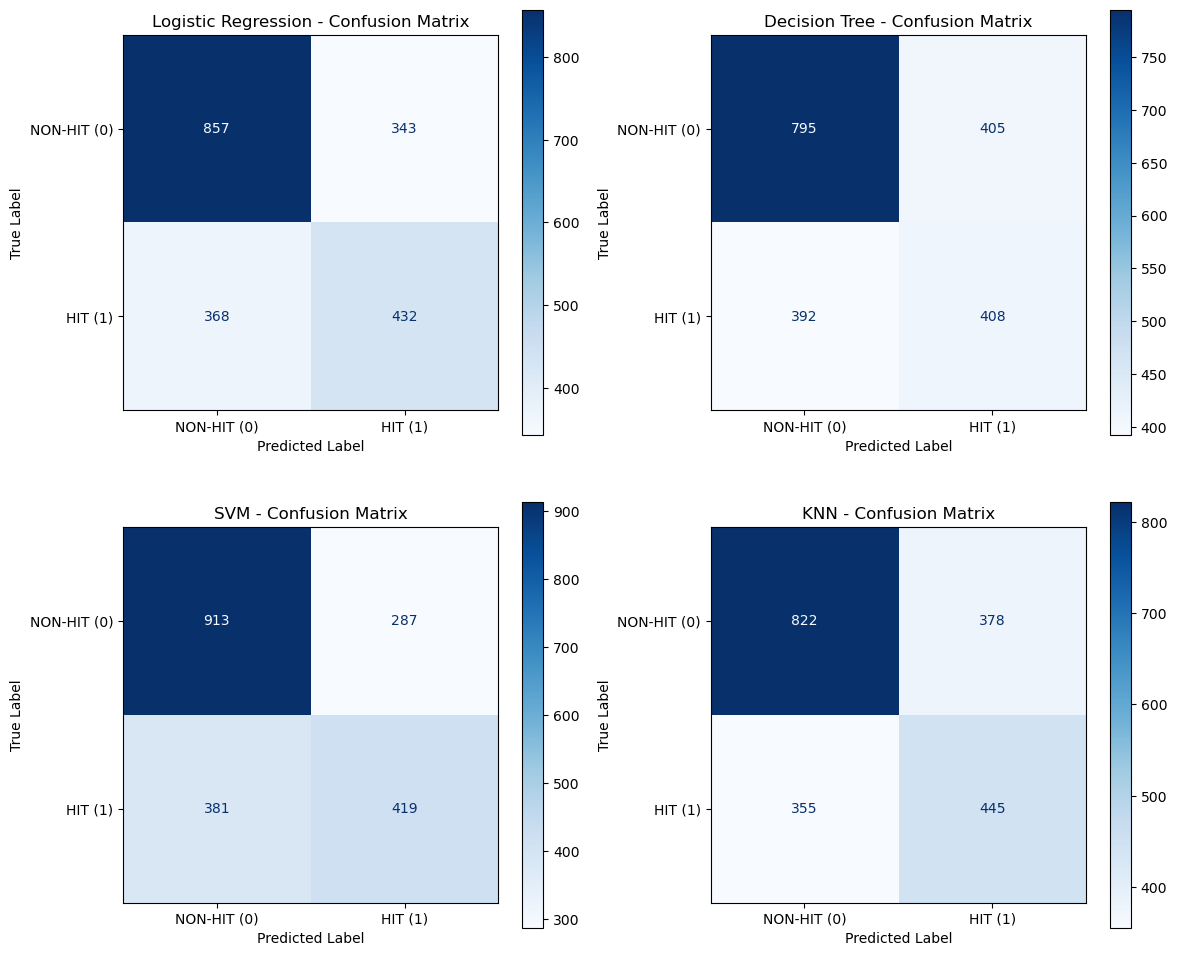

In [67]:
model_predictions = {
    "Logistic Regression": logistic_predictions,
    "Decision Tree": decision_tree_predictions,
    "SVM": svm_predictions,
    "KNN": knn_predictions,
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

model_axes = {
    "Logistic Regression": axes[0, 0],
    "Decision Tree": axes[0, 1],
    "SVM": axes[1, 0],
    "KNN": axes[1, 1],
}

for model_name, predictions in model_predictions.items():
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
    display_plot = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["NON-HIT (0)", "HIT (1)"],
    )
    display_plot.plot(
        ax=model_axes[model_name],
        cmap="Blues",
        values_format="d",
    )
    model_axes[model_name].set_title(f"{model_name} - Confusion Matrix")
    model_axes[model_name].set_xlabel("Predicted Label")
    model_axes[model_name].set_ylabel("True Label")

plt.tight_layout()
plt.show()

In [68]:
for model_name, predictions in model_predictions.items():
    print(f"{model_name} - Classification Report")
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["NON-HIT (0)", "HIT (1)"],
        zero_division=0,
    ))

Logistic Regression - Classification Report
              precision    recall  f1-score   support

 NON-HIT (0)       0.70      0.71      0.71      1200
     HIT (1)       0.56      0.54      0.55       800

    accuracy                           0.64      2000
   macro avg       0.63      0.63      0.63      2000
weighted avg       0.64      0.64      0.64      2000

Decision Tree - Classification Report
              precision    recall  f1-score   support

 NON-HIT (0)       0.67      0.66      0.67      1200
     HIT (1)       0.50      0.51      0.51       800

    accuracy                           0.60      2000
   macro avg       0.59      0.59      0.59      2000
weighted avg       0.60      0.60      0.60      2000

SVM - Classification Report
              precision    recall  f1-score   support

 NON-HIT (0)       0.71      0.76      0.73      1200
     HIT (1)       0.59      0.52      0.56       800

    accuracy                           0.67      2000
   macro avg      

## Confusion Matrix Analysis

A confusion matrix shows how many songs were correctly and incorrectly classified for each class. The rows represent the true labels, while the columns represent the predicted labels. The diagonal entries are correct predictions, and the off-diagonal entries are classification errors.

Based on the existing F1-score results, SVM currently performs best, with the highest F1-score among the four models.

## Hyperparameter Tuning

In [69]:
from sklearn.model_selection import GridSearchCV

tuning_configs = {
    "Logistic Regression": {
        "estimator": LogisticRegression(max_iter=1000, random_state=42),
        "parameters": {"C": [0.01, 0.1, 1, 10, 100]},
        "X_train": X_train_scaled,
        "X_test": X_test_scaled,
    },
    "Decision Tree": {
        "estimator": DecisionTreeClassifier(random_state=42),
        "parameters": {
            "max_depth": [3, 5, 7, 10, None],
            "min_samples_split": [2, 5, 10],
            "min_samples_leaf": [1, 2, 4],
        },
        "X_train": X_train,
        "X_test": X_test,
    },
    "SVM": {
        "estimator": SVC(random_state=42),
        "parameters": {
            "C": [0.1, 1, 10],
            "kernel": ["linear", "rbf"],
        },
        "X_train": X_train_scaled,
        "X_test": X_test_scaled,
    },
    "KNN": {
        "estimator": KNeighborsClassifier(),
        "parameters": {
            "n_neighbors": [3, 5, 7, 9, 11],
            "weights": ["uniform", "distance"],
        },
        "X_train": X_train_scaled,
        "X_test": X_test_scaled,
    },
}

tuned_models = {}
tuned_predictions = {}
tuned_results = []

for model_name, config in tuning_configs.items():
    grid_search = GridSearchCV(
        estimator=config["estimator"],
        param_grid=config["parameters"],
        cv=5,
        scoring="f1",
        n_jobs=-1,
    )
    grid_search.fit(config["X_train"], y_train)
    predictions = grid_search.predict(config["X_test"])

    tuned_models[model_name] = grid_search.best_estimator_
    tuned_predictions[model_name] = predictions
    tuned_results.append({
        "Model": model_name,
        "Best Parameters": grid_search.best_params_,
        "CV F1-score": grid_search.best_score_,
        "Test Accuracy": accuracy_score(y_test, predictions),
        "Test Precision": precision_score(y_test, predictions, zero_division=0),
        "Test Recall": recall_score(y_test, predictions, zero_division=0),
        "Test F1-score": f1_score(y_test, predictions, zero_division=0),
    })

    print(f"{model_name} best parameters: {grid_search.best_params_}")
    print(f"{model_name} best cross-validation F1-score: {grid_search.best_score_:.4f}")

tuned_results_df = pd.DataFrame(tuned_results).sort_values(
    "Test F1-score", ascending=False
).reset_index(drop=True)

display(tuned_results_df)

Logistic Regression best parameters: {'C': 100}
Logistic Regression best cross-validation F1-score: 0.5414
Decision Tree best parameters: {'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Decision Tree best cross-validation F1-score: 0.6226
SVM best parameters: {'C': 0.1, 'kernel': 'linear'}
SVM best cross-validation F1-score: 0.5810
KNN best parameters: {'n_neighbors': 3, 'weights': 'uniform'}
KNN best cross-validation F1-score: 0.5397


,Model,Best Parameters,CV F1-score,Test Accuracy,Test Precision,Test Recall,Test F1-score
0,Decision Tree,"{'max_depth': 3, 'min_samples_leaf': 1, 'min_s...",0.622624,0.6195,0.515688,0.80125,0.627509
1,SVM,"{'C': 0.1, 'kernel': 'linear'}",0.580974,0.6390,0.542299,0.62500,0.580720
2,Logistic Regression,{'C': 100},0.541385,0.6445,0.557419,0.54000,0.548571
3,KNN,"{'n_neighbors': 3, 'weights': 'uniform'}",0.539721,0.6190,0.523869,0.52125,0.522556


## Baseline vs Tuned Comparison

In [70]:
baseline_f1 = results_df[["model", "f1_score"]].rename(columns={
    "model": "Model",
    "f1_score": "Baseline F1-score",
})
tuned_f1 = tuned_results_df[["Model", "Test F1-score"]].rename(columns={
    "Test F1-score": "Tuned F1-score",
})

baseline_tuned_comparison_df = baseline_f1.merge(tuned_f1, on="Model")
baseline_tuned_comparison_df["F1-score Change"] = (
    baseline_tuned_comparison_df["Tuned F1-score"]
    - baseline_tuned_comparison_df["Baseline F1-score"]
)

display(baseline_tuned_comparison_df)
best_tuned_model = tuned_results_df.iloc[0]
print(
    f"Highest tuned test F1-score: {best_tuned_model['Model']} "
    f"({best_tuned_model['Test F1-score']:.4f})"
)

,Model,Baseline F1-score,Tuned F1-score,F1-score Change
0,SVM,0.556441,0.580720,0.024279
1,Logistic Regression,0.548571,0.548571,0.000000
2,KNN,0.548367,0.522556,-0.025811
3,Decision Tree,0.505890,0.627509,0.121619


Highest tuned test F1-score: Decision Tree (0.6275)


## Hyperparameter Tuning Analysis

Hyperparameter tuning was performed to systematically evaluate reasonable parameter combinations using five-fold cross-validation and F1-score, rather than relying only on the baseline defaults. This helps identify settings that balance precision and recall for HIT songs.

The comparison table shows that Decision Tree improved the most compared with its baseline, increasing its test F1-score from 0.5059 to 0.6275. Decision Tree also has the highest tuned test F1-score at 0.6275. Overall performance improved because the best tuned test F1-score is higher than the best baseline F1-score of 0.5564.

## Final Model Evaluation

In [71]:
best_tuned_decision_tree = tuned_models["Decision Tree"]
final_predictions = best_tuned_decision_tree.predict(X_test)

final_accuracy = accuracy_score(y_test, final_predictions)
final_precision = precision_score(y_test, final_predictions, zero_division=0)
final_recall = recall_score(y_test, final_predictions, zero_division=0)
final_f1_score = f1_score(y_test, final_predictions, zero_division=0)

print(f"Accuracy: {final_accuracy:.4f}")
print(f"Precision: {final_precision:.4f}")
print(f"Recall: {final_recall:.4f}")
print(f"F1-score: {final_f1_score:.4f}")

Accuracy: 0.6195
Precision: 0.5157
Recall: 0.8013
F1-score: 0.6275


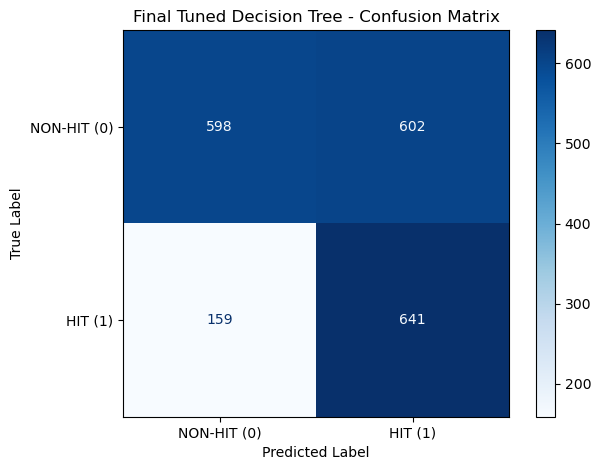

In [72]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    labels=[0, 1],
    display_labels=["NON-HIT (0)", "HIT (1)"],
    cmap="Blues",
    values_format="d",
)
plt.title("Final Tuned Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

In [73]:
print("Final Tuned Decision Tree - Classification Report")
print(classification_report(
    y_test,
    final_predictions,
    labels=[0, 1],
    target_names=["NON-HIT (0)", "HIT (1)"],
    zero_division=0,
))

Final Tuned Decision Tree - Classification Report
              precision    recall  f1-score   support

 NON-HIT (0)       0.79      0.50      0.61      1200
     HIT (1)       0.52      0.80      0.63       800

    accuracy                           0.62      2000
   macro avg       0.65      0.65      0.62      2000
weighted avg       0.68      0.62      0.62      2000



## Final Model Analysis

The tuned Decision Tree was selected as the final model because it achieved the highest tuned test F1-score. Its final accuracy, precision, recall, and F1-score are reported in the evaluation output above. Recall measures the proportion of actual HIT songs that the model correctly identifies, so a higher recall means fewer HIT songs are missed. The final model is the tuned Decision Tree fitted through the existing GridSearchCV process.

## Final Results Visualization

In [ ]:
model_order = ["Logistic Regression", "Decision Tree", "SVM", "KNN"]
baseline_scores = [
    results_df.loc[results_df["model"] == model, "f1_score"].iloc[0]
    for model in model_order
]
tuned_scores = [
    tuned_results_df.loc[tuned_results_df["Model"] == model, "Test F1-score"].iloc[0]
    for model in model_order
]

x_positions = np.arange(len(model_order))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(11, 6))
baseline_bars = ax.bar(
    x_positions - bar_width / 2,
    baseline_scores,
    bar_width,
    label="Baseline",
    color="steelblue",
)
tuned_bars = ax.bar(
    x_positions + bar_width / 2,
    tuned_scores,
    bar_width,
    label="Tuned",
    color="darkorange",
)

ax.set_title("Baseline vs Tuned Model F1-Score")
ax.set_xlabel("Model")
ax.set_ylabel("F1-score")
ax.set_xticks(x_positions)
ax.set_xticklabels(model_order, rotation=15, ha="right")
ax.set_ylim(0, 0.75)
ax.legend()

for bars in [baseline_bars, tuned_bars]:
    ax.bar_label(bars, fmt="%.4f", padding=3)

fig.tight_layout()
plt.show()

In [ ]:
final_model_summary_df = pd.DataFrame([{
    "Model": "Tuned Decision Tree",
    "Accuracy": final_accuracy,
    "Precision": final_precision,
    "Recall": final_recall,
    "F1-score": final_f1_score,
}])

display(final_model_summary_df)

## Final Conclusion

Four classification models were evaluated. Hyperparameter tuning was performed using GridSearchCV with 5-fold cross-validation and F1-score as the scoring metric. The tuned Decision Tree achieved the highest test F1-score. Its final Accuracy was 61.95%, Precision was 51.57%, Recall was 80.13%, and F1-score was 62.75%.

The Decision Tree improved from a baseline F1-score of 50.59% to a tuned F1-score of 62.75%, an improvement of 0.1216. The high recall means that the model identifies a large proportion of actual HIT songs, although precision remains comparatively lower. These results do not establish that the model is highly accurate or production-ready.